<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/01-linear-regression/code/optimize_sphere_2D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [31]:
def sphere_nd(x):
  """
  f(x)=∑i=1nx2i
  x: có thể là list hoặc numpy array
  return: tổng bình phương các phần tử trong x
  """
  # convert list to numpy array
  x = np.array(x)
  result = sum(x**2)
  return result

# gradient
def gradient(x, y):
    dx = 2*x
    dy = 2*y
    return dx, dy


Điểm bắt đầu ngẫu nhiên: x0 = (95.0000, -11.0000), f(x0, y0) = 9146.0000

Quá trình tối ưu hóa 2D:
Bước 01: x = (76.000000, -8.800000), f(x, y) = 5853.440000
Bước 02: x = (60.800000, -7.040000), f(x, y) = 3746.201600
Bước 03: x = (48.640000, -5.632000), f(x, y) = 2397.569024
Bước 04: x = (38.912000, -4.505600), f(x, y) = 1534.444175
Bước 05: x = (31.129600, -3.604480), f(x, y) = 982.044272
Bước 06: x = (24.903680, -2.883584), f(x, y) = 628.508334
Bước 07: x = (19.922944, -2.306867), f(x, y) = 402.245334
Bước 08: x = (15.938355, -1.845494), f(x, y) = 257.437014
Bước 09: x = (12.750684, -1.476395), f(x, y) = 164.759689
Bước 10: x = (10.200547, -1.181116), f(x, y) = 105.446201


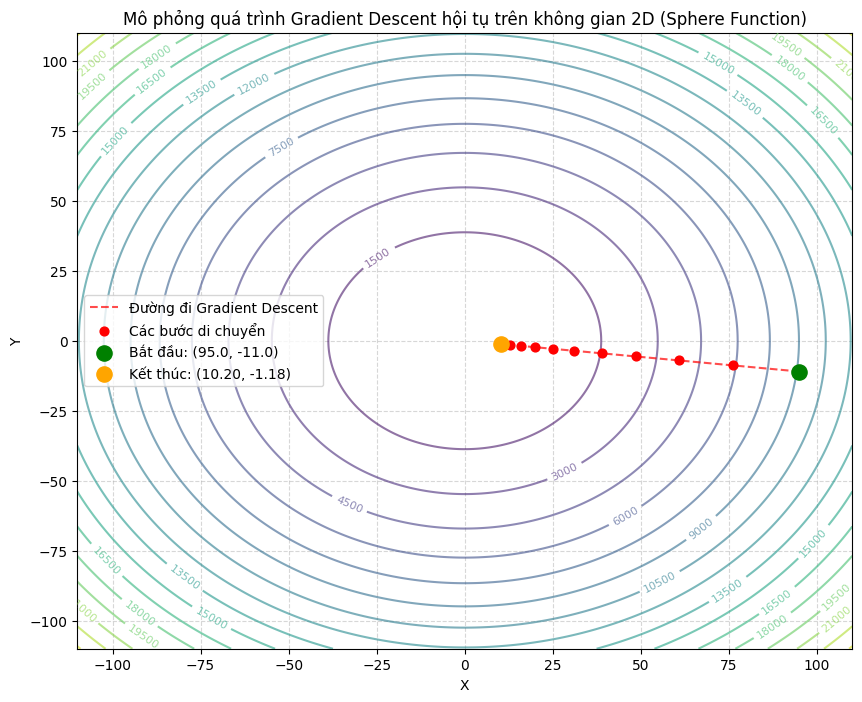

In [37]:
# --- GRADIENT DESCENT 2D VỚI LỊCH SỬ CHI TIẾT ---
num_steps_2d = 10
lr_2d = 0.1

# Khởi tạo điểm bắt đầu ngẫu nhiên cho không gian 2D
x_current_2d = random.randint(-100, 100)
y_current_2d = random.randint(-100, 100)

# Khởi tạo danh sách lưu lịch sử tọa độ và giá trị hàm số f(x, y)
x_history_2d = [x_current_2d]
y_history_2d = [y_current_2d]
z_history_2d = [sphere_nd([x_current_2d, y_current_2d])]

print(f"Điểm bắt đầu ngẫu nhiên: x0 = ({x_current_2d:.4f}, {y_current_2d:.4f}), f(x0, y0) = {z_history_2d[0]:.4f}\n")
print("Quá trình tối ưu hóa 2D:")
for step_idx in range(1, num_steps_2d + 1):
    # 1. Tính đạo hàm tại điểm hiện tại
    dx, dy = gradient(x_current_2d, y_current_2d)

    # 2. Cập nhật vị trí mới
    x_current_2d = x_current_2d - lr_2d * dx
    y_current_2d = y_current_2d - lr_2d * dy
    z_current_2d = sphere_nd([x_current_2d, y_current_2d])

    # Lưu lịch sử
    x_history_2d.append(x_current_2d)
    y_history_2d.append(y_current_2d)
    z_history_2d.append(z_current_2d)

    print(f"Bước {step_idx:02d}: x = ({x_current_2d:.6f}, {y_current_2d:.6f}), f(x, y) = {z_current_2d:.6f}")

# --- VẼ ĐỒ THỊ MINH HỌA QUÁ TRÌNH DI CHUYỂN 2D ---
plt.figure(figsize=(10, 8))

# Tạo lưới tọa độ phẳng để vẽ đường contour nền
x_vals = np.linspace(-110, 110, 400)
y_vals = np.linspace(-110, 110, 400)
X, Y = np.meshgrid(x_vals, y_vals)
Z = X**2 + Y**2

# Vẽ các đường đồng đẳng
contour = plt.contour(X, Y, Z, levels=20, cmap='viridis', alpha=0.6)
plt.clabel(contour, inline=True, fontsize=8)

# Vẽ toàn bộ quá trình di chuyển của các bước
plt.plot(x_history_2d, y_history_2d, color="red", linestyle="--", alpha=0.7, label="Đường đi Gradient Descent")
plt.scatter(x_history_2d, y_history_2d, color="red", s=40, zorder=5, label="Các bước di chuyển")

# Đánh dấu điểm bắt đầu (màu xanh lá) và điểm kết thúc (màu cam)
plt.scatter(x_history_2d[0], y_history_2d[0], color="green", s=120, zorder=6,
            label=f"Bắt đầu: ({x_history_2d[0]:.1f}, {y_history_2d[0]:.1f})")
plt.scatter(x_history_2d[-1], y_history_2d[-1], color="orange", s=120, zorder=6,
            label=f"Kết thúc: ({x_history_2d[-1]:.2f}, {y_history_2d[-1]:.2f})")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Mô phỏng quá trình Gradient Descent hội tụ trên không gian 2D (Sphere Function)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()